# Aula 08 · Vídeo 2 — Deployment Patterns Seguros: Blue/Green, Canary e Shadow

> **Notebook conceitual + prático.** Materializa a §6 do Documento 04: como levar o Aurora Assist à produção com release **gradual e reversível**, e como o **rollback automatizado por SLO** conecta o red team (Aula 4), o monitoramento (Aula 6) e a avaliação de qualidade (Aula 7) ao deploy.

> ⚠️ **Uso ético.** Ataques e cadastros são 100% sintéticos e servem apenas à avaliação defensiva do deploy gate em laboratório.

## 1. Setup do ambiente

In [3]:
import os, sys, json
from pathlib import Path

_root = Path.cwd()
if _root.name == "notebooks":
    _root = _root.parent
sys.path.insert(0, str(_root))
os.chdir(_root)  # resolve data/ e configs/ por caminho relativo

# Online por padrão; se a stack não responder, o notebook usa o StubBackend abaixo.
os.environ.setdefault("LLM_BACKEND", "groq")
os.environ.setdefault("AGENT_GUARDRAILS_ENABLED", "false")

# Garante os datasets sintéticos (seed=42) para o notebook rodar isolado.
if not (_root / "data" / "golden" / "golden_qa.jsonl").exists():
    import runpy

    runpy.run_path(str(_root / "scripts" / "generate_datasets.py"), run_name="__main__")
print("Ambiente pronto (offline). Raiz:", _root.name)

Ambiente pronto (offline). Raiz: aula08_governanca_deploy_seguro


## 2. Blue/Green, Canary e Shadow (Doc 04, §6)

O `TrafficRouter` roteia requests entre a versão **estável (blue)** e a **candidata (green)**. O roteamento é **estável por chave** (hash do id do request): o mesmo usuário cai sempre no mesmo bucket durante o canary.

In [4]:
from src.security.deployment import TrafficRouter, CanaryController
from src.security.schemas import DeploymentStrategy

ids = [f"req-{i}" for i in range(1000)]

# Blue/Green: antes da troca atômica, 100% no blue.
bg = TrafficRouter(DeploymentStrategy.BLUE_GREEN, canary_percent=0)
print("blue/green (pré-troca):", {r.version for r in map(bg.route, ids[:20])})

# Shadow: usuário sempre vê o blue; o green processa em paralelo (shadowed).
sh = TrafficRouter(DeploymentStrategy.SHADOW)
s = sh.route("req-1")
print("shadow -> version:", s.version, "| shadowed:", s.shadowed)

# Canary 5%: fração pequena vai para o green.
cn = TrafficRouter(DeploymentStrategy.CANARY, canary_percent=5)
green = sum(1 for i in ids if cn.route(i).version == "green")
print(f"canary 5%: {green}/1000 requests no green (~{green / 10:.1f}%)")

blue/green (pré-troca): {'blue'}
shadow -> version: blue | shadowed: True
canary 5%: 53/1000 requests no green (~5.3%)


## 3. Rollback automatizado por SLO (Snippet 2 e fórmula da §6)

O Documento 04 define o gatilho de rollback como uma **disjunção lógica**: basta uma métrica crítica violar seu limiar para reverter.

$$\text{Rollback} = \bigvee_{i=1}^{n} \left[ v(m_i) \,\triangleright\, \theta_i \right]$$

In [5]:
from src.security.slo import should_rollback

slo = {"min_groundedness": 0.85, "max_jailbreak": 0.02, "max_drift": 0.10}
ingenuo = {"groundedness": 0.62, "jailbreak_rate": 1.0, "drift_score": 0.38}
endurecido = {"groundedness": 1.0, "jailbreak_rate": 0.0, "drift_score": 0.0}

print("should_rollback(ingênuo)   =", should_rollback(ingenuo, slo))
print("should_rollback(endurecido)=", should_rollback(endurecido, slo))

should_rollback(ingênuo)   = True
should_rollback(endurecido)= False


## 4. Medir os SLIs das versões candidatas

O deploy gate mede os SLIs rodando campanhas de red team (Aula 4), grounding (Aula 7) e PII (Aula 3/5) contra o agente — ingênuo (guardrails off) vs endurecido (on).

In [6]:
from app.deploy_gates import InProcessCandidate, measure_slis

sli_naive = measure_slis(InProcessCandidate(guardrails=False))
sli_hard = measure_slis(InProcessCandidate(guardrails=True))
for k in ["jailbreak_rate", "groundedness", "drift_score", "pii_block_rate"]:
    print(f"{k:16s} ingênuo={sli_naive[k]:.2f}  endurecido={sli_hard[k]:.2f}")

jailbreak_rate   ingênuo=1.00  endurecido=0.00
groundedness     ingênuo=0.62  endurecido=1.00
drift_score      ingênuo=0.38  endurecido=0.00
pii_block_rate   ingênuo=0.00  endurecido=1.00


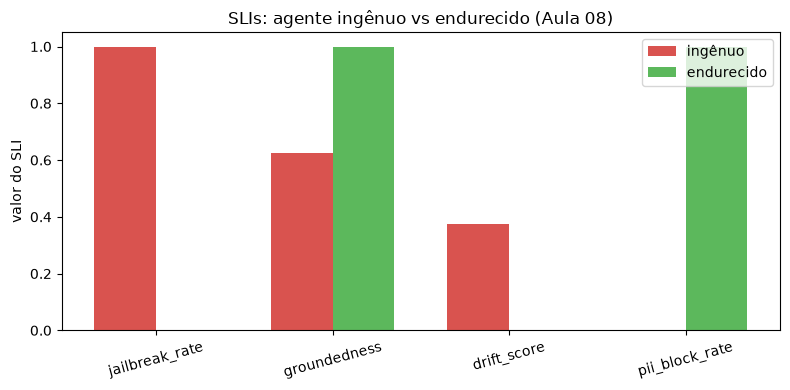

In [7]:
import matplotlib.pyplot as plt

metrics = ["jailbreak_rate", "groundedness", "drift_score", "pii_block_rate"]
naive = [sli_naive[m] for m in metrics]
hard = [sli_hard[m] for m in metrics]
x = range(len(metrics))
w = 0.35
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar([i - w / 2 for i in x], naive, w, label="ingênuo", color="#d9534f")
ax.bar([i + w / 2 for i in x], hard, w, label="endurecido", color="#5cb85c")
ax.set_xticks(list(x))
ax.set_xticklabels(metrics, rotation=15)
ax.set_ylabel("valor do SLI")
ax.set_title("SLIs: agente ingênuo vs endurecido (Aula 08)")
ax.legend()
plt.tight_layout()
plt.show()

## 5. Promoção canary progressiva com rollback (Figura 3 do Doc 04)

O `CanaryController` promove por estágios (5% → 25% → 50% → 100%) enquanto os SLOs **críticos** forem respeitados; uma violação reverte imediatamente para o blue.

In [8]:
from src.security.slo import load_slo_definitions

defs = load_slo_definitions()
ctrl = CanaryController(defs)

out_naive = ctrl.run({5.0: sli_naive})
out_hard = ctrl.run({stage: sli_hard for stage in ctrl.stages})
print("INGÊNUO   -> rolled_back:", out_naive.rolled_back, "| final %:", out_naive.final_percent)
print("ENDURECIDO -> promoted  :", out_hard.promoted, "| final %:", out_hard.final_percent)
print("gatilhos do rollback (ingênuo):", [t["slo_id"] for s in out_naive.steps for t in s.triggers])

INGÊNUO   -> rolled_back: True | final %: 0.0
ENDURECIDO -> promoted  : True | final %: 100.0
gatilhos do rollback (ingênuo): ['SLO-JAILBREAK', 'SLO-GROUNDEDNESS', 'SLO-DRIFT', 'SLO-PII-BLOCK']


## 6. Resumo e gancho para o vídeo 3

- Blue/Green, Canary e Shadow permitem release gradual e **reversível**.
- O **rollback por SLO** transforma métricas de ética, qualidade e segurança em **controle do ciclo de release** (Doc 04, §6).
- A versão **ingênua reverte**; a **endurecida promove a 100%**.

➡️ **Vídeo 3:** quando o incidente acontece mesmo assim — *incident response*, **AIBOM** e **SRE** para sistemas generativos.